## Access Satellite Wave CFOSAT SWIM QC (Zarr)
This Jupyter notebook demonstrates how to access and plot satellite_wave_cfosat_swim_qc data, available as a [Zarr](https://zarr.dev/) dataset stored on S3.

🔗 More information about the dataset is available [in the AODN metadata catalogue](https://catalogue-imos.aodn.org.au/geonetwork/srv/eng/catalog.search#/metadata/ee76e8ea-c48e-4580-92ef-e36b867ed6b0).

📌 The source of truth for this notebook is maintained on [GitHub](https://github.com/aodn/aodn_cloud_optimised/tree/main/notebooks/satellite_wave_cfosat_swim_qc.ipynb).

In [1]:
dataset_name = "satellite_wave_cfosat_swim_qc"

## Install/Update packages and Load common functions

In [2]:
import os, requests, importlib.util

open('setup.py', 'w').write(requests.get('https://raw.githubusercontent.com/aodn/aodn_cloud_optimised/main/notebooks/setup.py').text)

spec = importlib.util.spec_from_file_location("setup", "setup.py")
setup = importlib.util.module_from_spec(spec)
spec.loader.exec_module(setup)

setup.install_requirements()
setup.load_dataquery()

✅ Virtual environment already exists, skipping creation.


Using Python 3.12.3 environment at: /home/khannak/projects/AODN/aodn_cloud_optimised/aodn_cloud_optimised/.venv
Resolved 201 packages in 674ms
Checked 201 packages in 2ms


✅ Local version 0.3.30 is up to date (remote: 0.3.30)


In [3]:
from DataQuery import GetAodn

/home/khannak/projects/AODN/aodn_cloud_optimised/aodn_cloud_optimised/notebooks/DataQuery.py:4856: UserWarning: registration of accessor <class 'DataQuery.AODNAccessor'> under name 'aodn' for type <class 'pandas.core.frame.DataFrame'> is overriding a preexisting attribute with the same name.
  @pd.api.extensions.register_dataframe_accessor("aodn")


# Understanding the Dataset

In [ ]:
# remote zarr dataset
aodn = GetAodn()
dname = f'{dataset_name}.zarr'
%time aodn_dataset = aodn.get_dataset(dname)

In [ ]:
# #--- Non-production bucket (testing only; requires `aws sso login --profile <profile>`) ---
# import boto3
# profile, region = "edge-admin", "ap-southeast-2"
# creds = boto3.Session(profile_name=profile, region_name=region).get_credentials().get_frozen_credentials()
# aodn = GetAodn(
#     bucket_name="imos-optimised-nonproduction",
#     prefix="",
#     s3_fs_opts={
#         "key": creds.access_key,
#         "secret": creds.secret_key,
#         "token": creds.token,
#         "client_kwargs": {"endpoint_url": f"https://s3.{region}.amazonaws.com"},
#     },
# )
# dname = f'{dataset_name}.zarr'
# %time aodn_dataset = aodn.get_dataset(dname)

CPU times: user 194 ms, sys: 74.4 ms, total: 268 ms
Wall time: 729 ms


In [7]:
ds = aodn_dataset.zarr_store
ds.info()

xarray.Dataset {
dimensions:
	TIME = 762 ;
	DIRECTION = 12 ;
	WAVENUMBER = 32 ;

variables:
	float64 BOT_DEPTH_NEW(TIME) ;
		BOT_DEPTH_NEW:comment = source GEBCO 2019 grid with 15 arcsec resolution, DOI: 10.5285/836f016a-33be-6ddc-e053-6c86abc0788e ;
		BOT_DEPTH_NEW:long_name = sea_floor_depth_below_mean_sea_level ;
		BOT_DEPTH_NEW:positive = up ;
		BOT_DEPTH_NEW:reference_datum = Mean Sea Level (MSL) ;
		BOT_DEPTH_NEW:standard_name = sea_floor_depth_below_mean_sea_level ;
		BOT_DEPTH_NEW:units = m ;
		BOT_DEPTH_NEW:valid_max = 8845.0 ;
		BOT_DEPTH_NEW:valid_min = -10924.0 ;
	float32 DIRECTION(DIRECTION) ;
		DIRECTION:long_name = Direction (from) vector of the wave spectrum (clockwise from the geographic North, centre of the bin) ;
		DIRECTION:units = degrees ;
		DIRECTION:valid_max = 180.0 ;
		DIRECTION:valid_min = 0.0 ;
	float64 DIST2COAST(TIME) ;
		DIST2COAST:comment = source dist2coast_1deg_ocean.nc, 0.01-degree ocean grid, distributor PacIOOS, creator NASA/GSFC Ocean Color Group  

## Plot time coverage

In [8]:
aodn_dataset.get_temporal_extent()

(Timestamp('2019-04-25 03:32:14.012294016'),
 Timestamp('2024-10-05 14:36:19.071907008'))

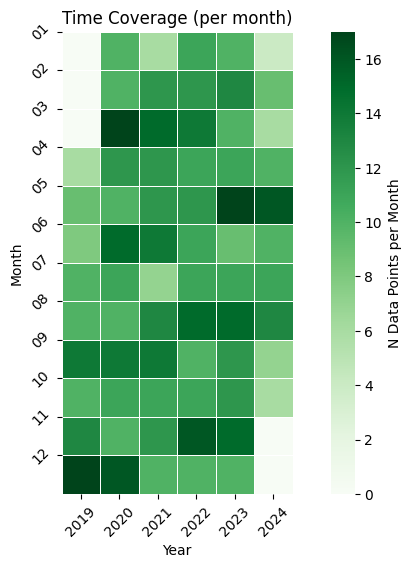

In [9]:
aodn_dataset.plot_time_coverage()

## Load SWIM Wave Data

**SWIM** (Surface Waves Investigation and Monitoring) is a Ku-band real-aperture radar on the China–France
Oceanography Satellite (**CFOSAT**, launched 2018). Its six beams (0°–10° incidence) rotate around the nadir,
so every patch of ocean is viewed from all azimuths. Long ocean waves tilt the sea surface and modulate the radar
backscatter; SWIM inverts that modulation into a **directional wave slope spectrum**.

This product aggregates the SWIM Level-2 data into **1° × 1° boxes**. Each `TIME` step is one satellite pass over one box,
with the box-mean `LATITUDE` / `LONGITUDE` attached. A box is revisited only every few days, so the record is a sparse,
irregular time series (about 10–15 passes per month), not a continuous station record.

| Group | Variables | Notes |
|---|---|---|
| **Directional spectrum** | `MSS` (10° beam), `MSS_COMBINED` (all beams) | dims `(TIME, WAVENUMBER, DIRECTION)`; 32 wavenumbers × 12 directions |
| **Integrated parameters** | `SWH`, `MWP`, `Lp`, `Dp` | significant wave height, mean period (Jiang et al., 2022), dominant wavelength, dominant direction |
| **Buoy-calibrated** | `*_CALIBRATED_NDBC` | SWIM values corrected against NDBC wave buoys; **use these for reporting** |
| **Model reference** | `*_WW3` | collocated WAVEWATCH III hindcast; for validation only, and may be missing (flag 9) in some boxes |
| **Ancillary** | `NADIR_RAIN_PERCENTAGE`, `LAND_COVERAGE_COMBINED`, `SEA_ICE_COVERAGE_COMBINED`, `DIST2COAST`, `BOT_DEPTH_NEW` | contamination and context |

**Two properties of the spectrum to keep in mind:**
- It is a **slope** spectrum, $S(k,\theta) = k^2 F(k,\theta)$, where $F$ is the familiar wave-height (elevation) spectrum.
  The $k^2$ weighting boosts short waves relative to a height spectrum.
- `DIRECTION` only spans 0°–180°: SWIM cannot tell whether a wave train travels towards θ or θ + 180° (the **180° ambiguity**).

Every variable carries an **IMOS QC flag**. Only flags 1 (*good*) and 2 (*probably good*) are kept below; flag 0 (*no QC performed*)
and 9 (*missing*) are discarded. The spectrum is flagged per (wavenumber, direction) bin, so a wavenumber is kept when at least
`MIN_DIRS` of its 12 direction bins are good, and the omnidirectional value is rescaled to the full 180°.

Set `BOX_LAT` / `BOX_LON` to the south-west corner of the 1° box to analyse (longitude 0–360°), or `None` to use the box with the most passes.

In [10]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
import warnings
warnings.filterwarnings("ignore")

# ---- User settings --------------------------------------------------------
BOX_LAT, BOX_LON = 12, 55      # SW corner of the 1°x1° box (lon 0–360); None -> most-sampled box
SPEC_VAR = "MSS"               # "MSS" (10° beam) or "MSS_COMBINED" (all beams)
GOOD     = [1, 2]              # IMOS QC flags kept: 1 = good, 2 = probably good
MIN_DIRS = 6                   # min good direction bins (of 12) to keep a wavenumber bin

# ---- Select one 1°x1° box -------------------------------------------------
ds_all  = aodn_dataset.zarr_store
box_lat = np.floor(ds_all["LATITUDE"].values)
box_lon = np.floor(ds_all["LONGITUDE"].values)
boxes   = pd.Series(list(zip(box_lat, box_lon))).value_counts()

if BOX_LAT is None or BOX_LON is None:
    BOX_LAT, BOX_LON = boxes.index[0]
in_box = (box_lat == BOX_LAT) & (box_lon == BOX_LON)
if not in_box.any():
    raise ValueError(f"No passes in box {BOX_LAT}°, {BOX_LON}°. Most-sampled boxes:\n{boxes.head(10)}")

xds = ds_all.isel(TIME=np.where(in_box)[0]).sortby("TIME").load()   # one box is small: load once
lon_w = BOX_LON - 360 if BOX_LON > 180 else BOX_LON
BOX_NAME = (f"{abs(BOX_LAT):.0f}–{abs(BOX_LAT) + 1:.0f}°{'N' if BOX_LAT >= 0 else 'S'}, "
            f"{abs(lon_w):.0f}–{abs(lon_w) + 1:.0f}°{'E' if lon_w >= 0 else 'W'}")

# ---- Helpers used by every plot below ------------------------------------
def qc(var, ds=None):
    """Variable with only good / probably-good values kept."""
    ds = xds if ds is None else ds
    return ds[var].where(ds[f"{var}_quality_control"].isin(GOOD))

def omni_spectrum(ds=None, var=None):
    """Omnidirectional slope spectrum (TIME, WAVENUMBER): QC-masked MSS summed over direction."""
    ds  = xds if ds is None else ds
    var = SPEC_VAR if var is None else var
    good  = qc(var, ds)
    n_ok  = good.notnull().sum("DIRECTION")
    omni  = good.mean("DIRECTION") * ds.sizes["DIRECTION"]       # rescale partial coverage to full 180°
    omni  = omni.where(n_ok >= MIN_DIRS).transpose("TIME", "WAVENUMBER")
    return omni.where(omni.notnull().any("WAVENUMBER"), drop=True)

# Deep-water dispersion (ω² = g k): T = 10 s -> λ ≈ 156 m ; T = 8 s -> λ ≈ 100 m
G = 9.81
K_SWELL = 4 * np.pi**2 / (G * 10**2)    # k below this: swell      (T > 10 s)
K_WIND  = 4 * np.pi**2 / (G * 8**2)     # k above this: wind sea   (T < 8 s)
BANDS = [
    (None,    K_SWELL, "#4575b4", "Swell (T > 10 s, λ > 156 m)"),
    (K_SWELL, K_WIND,  "#999999", "Transition (8–10 s)"),
    (K_WIND,  None,    "#d73027", "Wind sea (T < 8 s, λ < 100 m)"),
]
def k2wl(x):
    return 2 * np.pi / np.asarray(x, dtype=float)

# ---- Summary --------------------------------------------------------------
time_vals = xds["TIME"].values
t_min = pd.Timestamp(time_vals[0]).strftime("%Y-%m-%d")
t_max = pd.Timestamp(time_vals[-1]).strftime("%Y-%m-%d")
k  = xds["WAVENUMBER"].values
dr = xds["DIRECTION"].values
n_months = max(1, (pd.Timestamp(time_vals[-1]) - pd.Timestamp(time_vals[0])).days / 30.44)

print(f"Boxes in dataset: {len(boxes):,}   → selected box {BOX_NAME}")
print(f"Passes in box: {xds.sizes['TIME']:,} from {t_min} to {t_max} (~{xds.sizes['TIME'] / n_months:.0f} per month)")
print(f"Wavenumber: {k.min():.4f}–{k.max():.4f} m⁻¹ ({len(k)} bins) → wavelength {k2wl(k.max()):.0f}–{k2wl(k.min()):.0f} m")
print(f"Direction: {len(dr)} bins of {np.diff(dr).mean():.0f}° spanning 0–180° (180° ambiguity)")

print("\nQC flags kept (1/2) per variable:")
for v in [SPEC_VAR, "SWH", "SWH_CALIBRATED_NDBC", "MWP_CALIBRATED_NDBC", "Lp_CALIBRATED_NDBC", "SWH_WW3"]:
    f = xds[f"{v}_quality_control"].values.ravel()
    print(f"  {v:22s} {np.isin(f, GOOD).mean():6.1%} good   flags present: {sorted(pd.unique(f[~np.isnan(f)]).astype(int).tolist())}")
if not qc("SWH_WW3").notnull().any():
    print("\n⚠ No valid WW3 hindcast values in this box: model overlays are skipped below.")
print(f"\n{SPEC_VAR}: {xds[SPEC_VAR].attrs.get('long_name', '')} [{xds[SPEC_VAR].attrs.get('units', '')}]  dims {dict(xds[SPEC_VAR].sizes)}")

Boxes in dataset: 1   → selected box 12–13°N, 55–56°E
Passes in box: 762 from 2019-04-25 to 2024-10-05 (~12 per month)
Wavenumber: 0.0126–0.2789 m⁻¹ (32 bins) → wavelength 23–500 m
Direction: 12 bins of 15° spanning 0–180° (180° ambiguity)

QC flags kept (1/2) per variable:
  MSS                     84.2% good   flags present: [0, 1, 9]
  SWH                     88.8% good   flags present: [1, 9]
  SWH_CALIBRATED_NDBC     88.8% good   flags present: [1, 9]
  MWP_CALIBRATED_NDBC     88.8% good   flags present: [1, 9]
  Lp_CALIBRATED_NDBC      88.8% good   flags present: [1, 9]
  SWH_WW3                  0.0% good   flags present: [9]

⚠ No valid WW3 hindcast values in this box: model overlays are skipped below.

MSS: 2D wave slope spectrum from SWIM (10-degree beam) [m2]  dims {'TIME': 762, 'WAVENUMBER': 32, 'DIRECTION': 12}


## Wave Spectra Across Sea States

Omnidirectional slope spectra (`MSS` summed over direction) for six passes chosen to span the range of sea states,
from the 5th to the 99th percentile of NDBC-calibrated SWH. Single passes are noisy, so ordering them by SWH (rather than by date)
makes the physics visible:
- **Swell band** (λ > 156 m, left): long waves generated by distant storms; they travel thousands of km with little loss
- **Wind-sea band** (λ < 100 m, right): short, steep waves generated by the local wind
- **Spectral peak**: as the sea state grows, energy rises and the peak migrates to **longer wavelengths** (lower k).
  This "downshift" is the classic signature of a growing, maturing wave field

The band limits come from deep-water dispersion, $\omega^2 = g k$, so $\lambda = g T^2 / 2\pi$.
They are a rule of thumb: strictly, wind sea and swell are separated by wave age (wave phase speed vs. wind speed).
The y-axis is logarithmic so calm and stormy spectra can be compared on one plot.

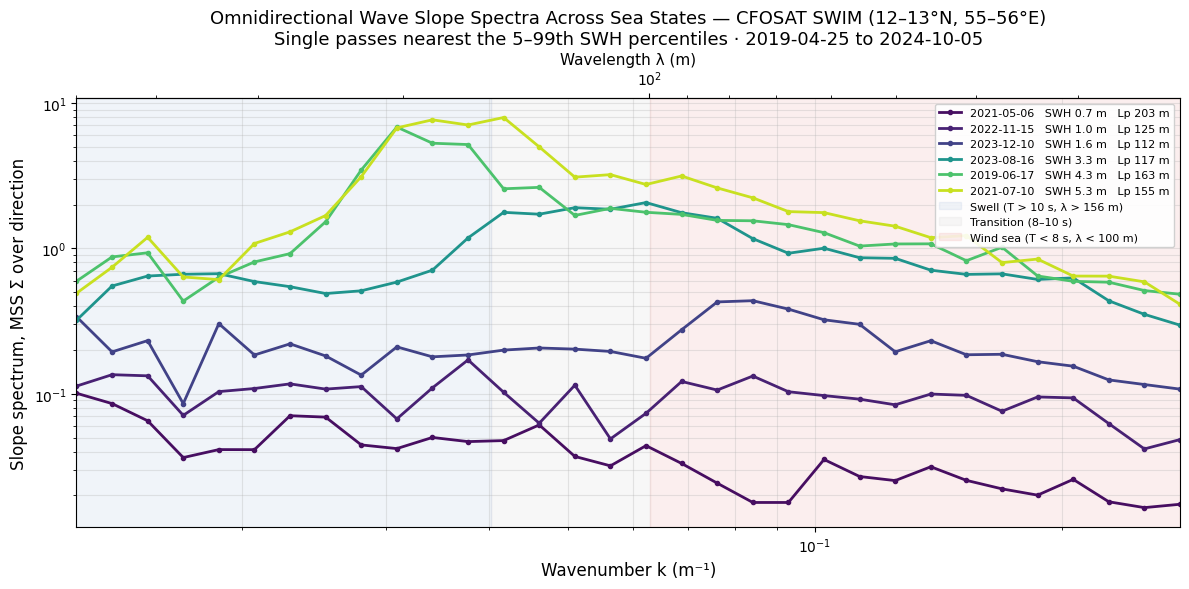

In [ ]:
DATE_START = "2019-04-25"        
DATE_END   = "2024-10-05"        
time_vals = xds["TIME"].values
DATE_START = DATE_START or pd.Timestamp(time_vals[0]).strftime("%Y-%m-%d")
DATE_END   = DATE_END   or pd.Timestamp(time_vals[-1]).strftime("%Y-%m-%d")

sub  = xds.sel(TIME=slice(DATE_START, DATE_END))
omni = omni_spectrum(sub)
swh  = qc("SWH_CALIBRATED_NDBC", sub).sel(TIME=omni.TIME)
lp   = qc("Lp_CALIBRATED_NDBC", sub).sel(TIME=omni.TIME)
k    = xds["WAVENUMBER"].values

# One pass nearest to each SWH percentile
swh_s = swh.to_series().dropna()
pick  = []
for q in [0.05, 0.25, 0.50, 0.75, 0.90, 0.99]:
    t = (swh_s - swh_s.quantile(q)).abs().idxmin()
    if t not in pick:
        pick.append(t)

fig, ax = plt.subplots(figsize=(12, 6))
cmap = plt.get_cmap("viridis")
norm = plt.Normalize(swh_s.min(), swh_s.max())

for t in sorted(pick, key=lambda t: swh_s[t]):
    spec  = omni.sel(TIME=t).dropna("WAVENUMBER")      # connect across QC-masked bins
    label = f"{pd.Timestamp(t):%Y-%m-%d}   SWH {swh_s[t]:.1f} m   Lp {float(lp.sel(TIME=t)):.0f} m"
    ax.plot(spec.WAVENUMBER, spec, color=cmap(norm(swh_s[t])), lw=2, marker="o", ms=3, label=label)

# Spectral band shading
for klo, khi, col, lbl in BANDS:
    ax.axvspan(klo or k.min(), khi or k.max(), color=col, alpha=0.08, label=lbl)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(k.min(), k.max())
ax.set_xlabel("Wavenumber k (m⁻¹)", fontsize=12)
ax.set_ylabel(f"Slope spectrum, {SPEC_VAR} Σ over direction", fontsize=12)
top = ax.secondary_xaxis("top", functions=(k2wl, k2wl))
top.set_xlabel("Wavelength λ (m)", fontsize=11)
ax.set_title(
    f"Omnidirectional Wave Slope Spectra Across Sea States — CFOSAT SWIM ({BOX_NAME})\n"
    f"Single passes nearest the 5–99th SWH percentiles · {DATE_START} to {DATE_END}",
    fontsize=13,
)
ax.legend(fontsize=8, loc="upper right", framealpha=0.9)
ax.grid(True, alpha=0.3, which="both")
plt.tight_layout()
plt.show()

## Spectral Hovmöller Diagram

Wavenumber–time heatmap of the **monthly median** omnidirectional spectrum. Monthly (not daily) bins are needed because a
1° box is only revisited every few days; the median is used because single passes are noisy and occasionally extreme.
- **Bright columns** are energetic months; the brightest energy sits at the dominant wave scale
- **Grey cells** are months with fewer than `MIN_PASSES` valid passes (*no data*, not *calm sea*)
- The **cyan line** is the monthly median dominant wavenumber $k_p = 2\pi / L_p$ from the calibrated `Lp`.
  It drops (towards longer waves) when swell dominates
- Dashed lines mark the swell / wind-sea band limits

The colour scale is logarithmic: wave energy varies by orders of magnitude between calm and stormy seasons, and a linear
scale would hide the structure of the calm months. In monsoon regions such as the Arabian Sea, the Jun–Sep south-west
monsoon produces some of the most energetic seasonal wave climates on Earth. In the Southern Ocean the equivalent peak is in austral winter.

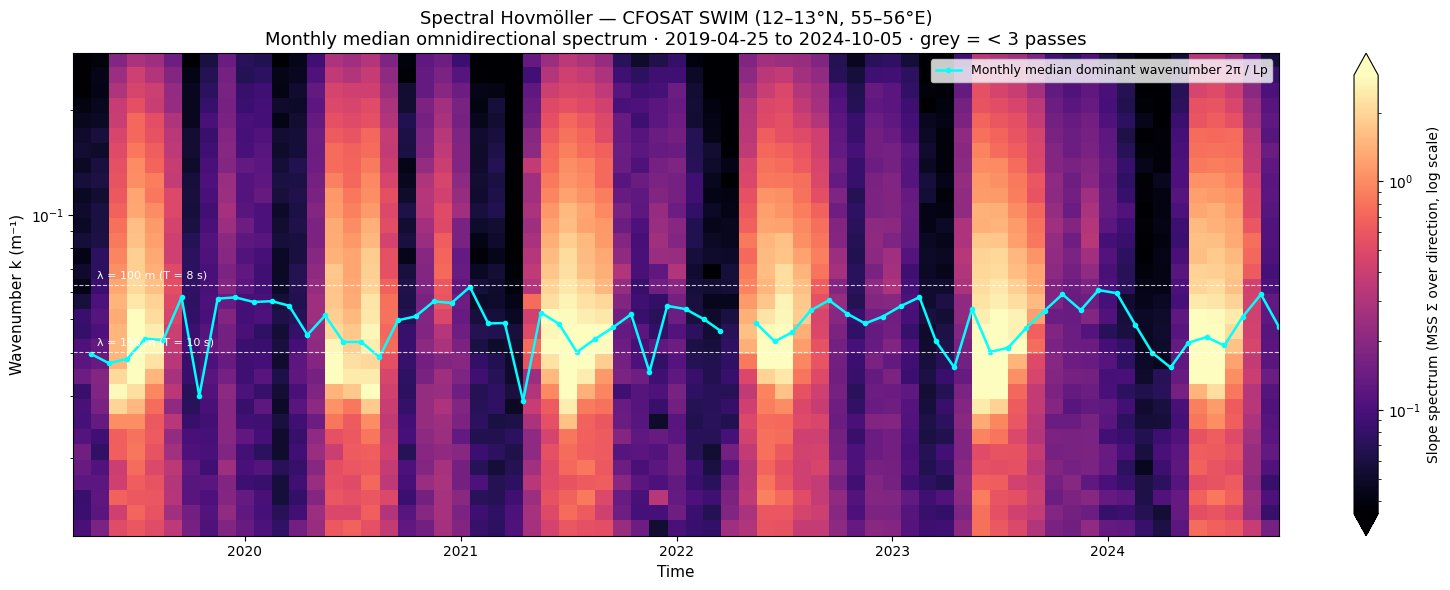

In [13]:
DATE_START = "2019-04-25"        
DATE_END   = "2024-10-05"
MIN_PASSES = 3           # months with fewer valid passes are shown grey
time_vals = xds["TIME"].values
DATE_START = DATE_START or pd.Timestamp(time_vals[0]).strftime("%Y-%m-%d")
DATE_END   = DATE_END   or pd.Timestamp(time_vals[-1]).strftime("%Y-%m-%d")

sub  = xds.sel(TIME=slice(DATE_START, DATE_END))
omni = omni_spectrum(sub)
n_pm = omni.notnull().any("WAVENUMBER").resample(TIME="1MS").sum()
monthly = omni.resample(TIME="1MS").median().where(n_pm >= MIN_PASSES)

lp_m = qc("Lp_CALIBRATED_NDBC", sub).resample(TIME="1MS").median().where(n_pm >= MIN_PASSES)
kp_m = 2 * np.pi / lp_m

vals = monthly.values[np.isfinite(monthly.values) & (monthly.values > 0)]
cmap = plt.get_cmap("magma").copy()
cmap.set_bad("lightgrey")

fig, ax = plt.subplots(figsize=(16, 6))
monthly.plot(
    x="TIME", y="WAVENUMBER",
    ax=ax, cmap=cmap,
    norm=LogNorm(vmin=np.percentile(vals, 2), vmax=np.percentile(vals, 98)),
    cbar_kwargs={"label": f"Slope spectrum ({SPEC_VAR} Σ over direction, log scale)", "extend": "both"},
)
ax.plot(kp_m.TIME + pd.Timedelta(days=15), kp_m, color="cyan", lw=1.8, marker="o", ms=3,
        label="Monthly median dominant wavenumber 2π / Lp")

# Mark band boundaries
for kb, lbl in [(K_SWELL, "λ = 156 m (T = 10 s)"), (K_WIND, "λ = 100 m (T = 8 s)")]:
    ax.axhline(kb, color="white", lw=0.8, ls="--", alpha=0.8)
    ax.text(pd.Timestamp(DATE_START), kb * 1.03, lbl, color="white", fontsize=8, va="bottom")

ax.set_yscale("log")
ax.set_title(
    f"Spectral Hovmöller — CFOSAT SWIM ({BOX_NAME})\n"
    f"Monthly median omnidirectional spectrum · {DATE_START} to {DATE_END} · grey = < {MIN_PASSES} passes",
    fontsize=13,
)
ax.set_xlabel("Time", fontsize=11)
ax.set_ylabel("Wavenumber k (m⁻¹)", fontsize=11)
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

## Key Wave Parameters with Variability Envelope

Time series of the four integrated SWIM parameters for every pass:

| Parameter | Variable | Meaning |
|---|---|---|
| **SWH** | `SWH_CALIBRATED_NDBC` | significant wave height, $H_s = 4\sqrt{m_0}$: roughly the mean height of the highest third of waves |
| **MWP** | `MWP_CALIBRATED_NDBC` | mean wave period, from the Jiang et al. (2022) SWIM algorithm |
| **Lp** | `Lp_CALIBRATED_NDBC` | dominant wavelength, at the spectral peak |
| **Dp** | `Dp` | dominant direction the waves come **from** (°, clockwise from N). No calibrated version exists |

Grey dots are raw SWIM values and coloured dots are the NDBC-calibrated values used for reporting.
The black dashed line is the 30-day running median, and the shaded envelope is its 16th–84th percentile range
(≈ ±1σ for a normal distribution). A wide envelope means variable conditions within the month, such as passing storms or swell events.
The collocated WW3 hindcast (orange) is overlaid where it exists.

Because of the 180° ambiguity, `Dp` is shown as individual passes coloured by SWH rather than as a running average:
an average of directions near 0° and 180° would be meaningless.

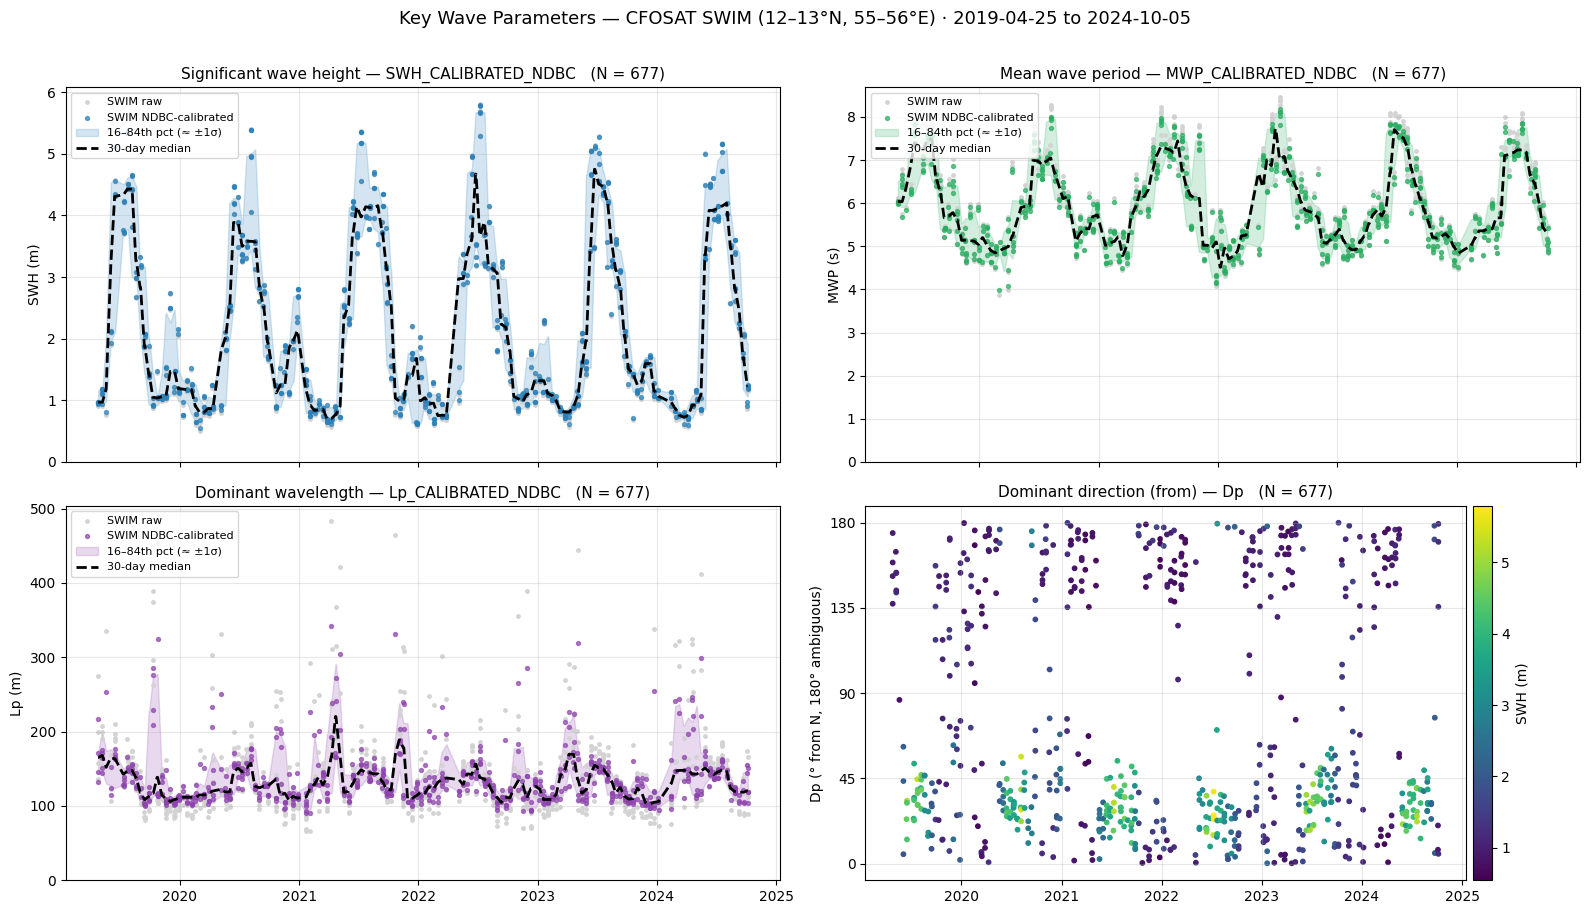

In [14]:
DATE_START = "2019-04-25"        
DATE_END   = "2024-10-05"
time_vals = xds["TIME"].values
DATE_START = DATE_START or pd.Timestamp(time_vals[0]).strftime("%Y-%m-%d")
DATE_END   = DATE_END   or pd.Timestamp(time_vals[-1]).strftime("%Y-%m-%d")

PARAMS = {
    "SWH": ("Significant wave height", "SWH (m)",  "#2980b9"),
    "MWP": ("Mean wave period",        "MWP (s)",  "#27ae60"),
    "Lp":  ("Dominant wavelength",     "Lp (m)",   "#8e44ad"),
}

sub = xds.sel(TIME=slice(DATE_START, DATE_END))
fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharex=True)
axes = axes.flatten()

for ax, (var, (name, ylab, color)) in zip(axes, PARAMS.items()):
    raw = qc(var, sub).to_series()
    cal = qc(f"{var}_CALIBRATED_NDBC", sub).to_series().dropna()
    ww3 = qc(f"{var}_WW3", sub).to_series().dropna()

    ax.scatter(raw.index, raw.values, s=6, color="lightgrey", label="SWIM raw", zorder=1)
    ax.scatter(cal.index, cal.values, s=8, color=color, alpha=0.7, label="SWIM NDBC-calibrated", zorder=2)

    if len(cal) > 5:
        roll = cal.rolling("30D", center=True, min_periods=3)
        ax.fill_between(cal.index, roll.quantile(0.16), roll.quantile(0.84),
                        color=color, alpha=0.2, label="16–84th pct (≈ ±1σ)", zorder=0)
        ax.plot(cal.index, roll.median(), color="k", lw=2, ls="--", label="30-day median", zorder=3)
    if len(ww3) > 5:
        ax.plot(ww3.index, ww3.rolling("30D", center=True, min_periods=3).median(),
                color="#e67e22", lw=1.8, label="WW3 hindcast (30-day median)", zorder=3)

    ax.set_title(f"{name} — {var}_CALIBRATED_NDBC   (N = {len(cal):,})", fontsize=11)
    ax.set_ylabel(ylab, fontsize=10)
    ax.set_ylim(bottom=0)
    ax.legend(fontsize=8, loc="upper left")
    ax.grid(True, alpha=0.3)

# Dominant direction (axial, so no running mean)
ax  = axes[3]
dp  = qc("Dp", sub).to_series()
swh = qc("SWH_CALIBRATED_NDBC", sub).to_series()
ok  = dp.notna() & swh.notna()
sc  = ax.scatter(dp.index[ok], dp[ok], c=swh[ok], s=10, cmap="viridis")
plt.colorbar(sc, ax=ax, label="SWH (m)", pad=0.01)
ax.set_title(f"Dominant direction (from) — Dp   (N = {ok.sum():,})", fontsize=11)
ax.set_ylabel("Dp (° from N, 180° ambiguous)", fontsize=10)
ax.set_yticks(np.arange(0, 361, 45) if dp.max() > 180 else np.arange(0, 181, 45))
ax.grid(True, alpha=0.3)

for ax in axes[2:]:
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

fig.suptitle(
    f"Key Wave Parameters — CFOSAT SWIM ({BOX_NAME}) · {DATE_START} to {DATE_END}",
    fontsize=13, y=1.01,
)
plt.tight_layout()
plt.show()

## Sea-State Character and Data Quality

Two derived indicators describe *what kind* of sea is present, alongside an indicator of observation quality:

| Panel | Quantity | Interpretation |
|---|---|---|
| **Wave steepness** | $H_s / L_p$ | ≈ 0.022 for a fully developed wind sea (Pierson–Moskowitz). Higher values mean a young, actively growing wind sea; values below ~0.01 mean long, low swell |
| **Swell-dominated passes** | monthly % of passes with $L_p$ > 156 m (T > 10 s) | how often long-period swell, rather than local wind sea, carries the dominant energy |
| **Data quality** | % of spectral bins with good QC; `NADIR_RAIN_PERCENTAGE` | rain attenuates and scatters the Ku-band signal, so rainy passes are less reliable |

Steepness is a measure of wave age: as a wind sea grows, its waves lengthen faster than they grow in height,
so $H_s/L_p$ falls. Dips in the good-QC percentage often coincide with rain or with very low sea states, where the modulation
signal is weak.

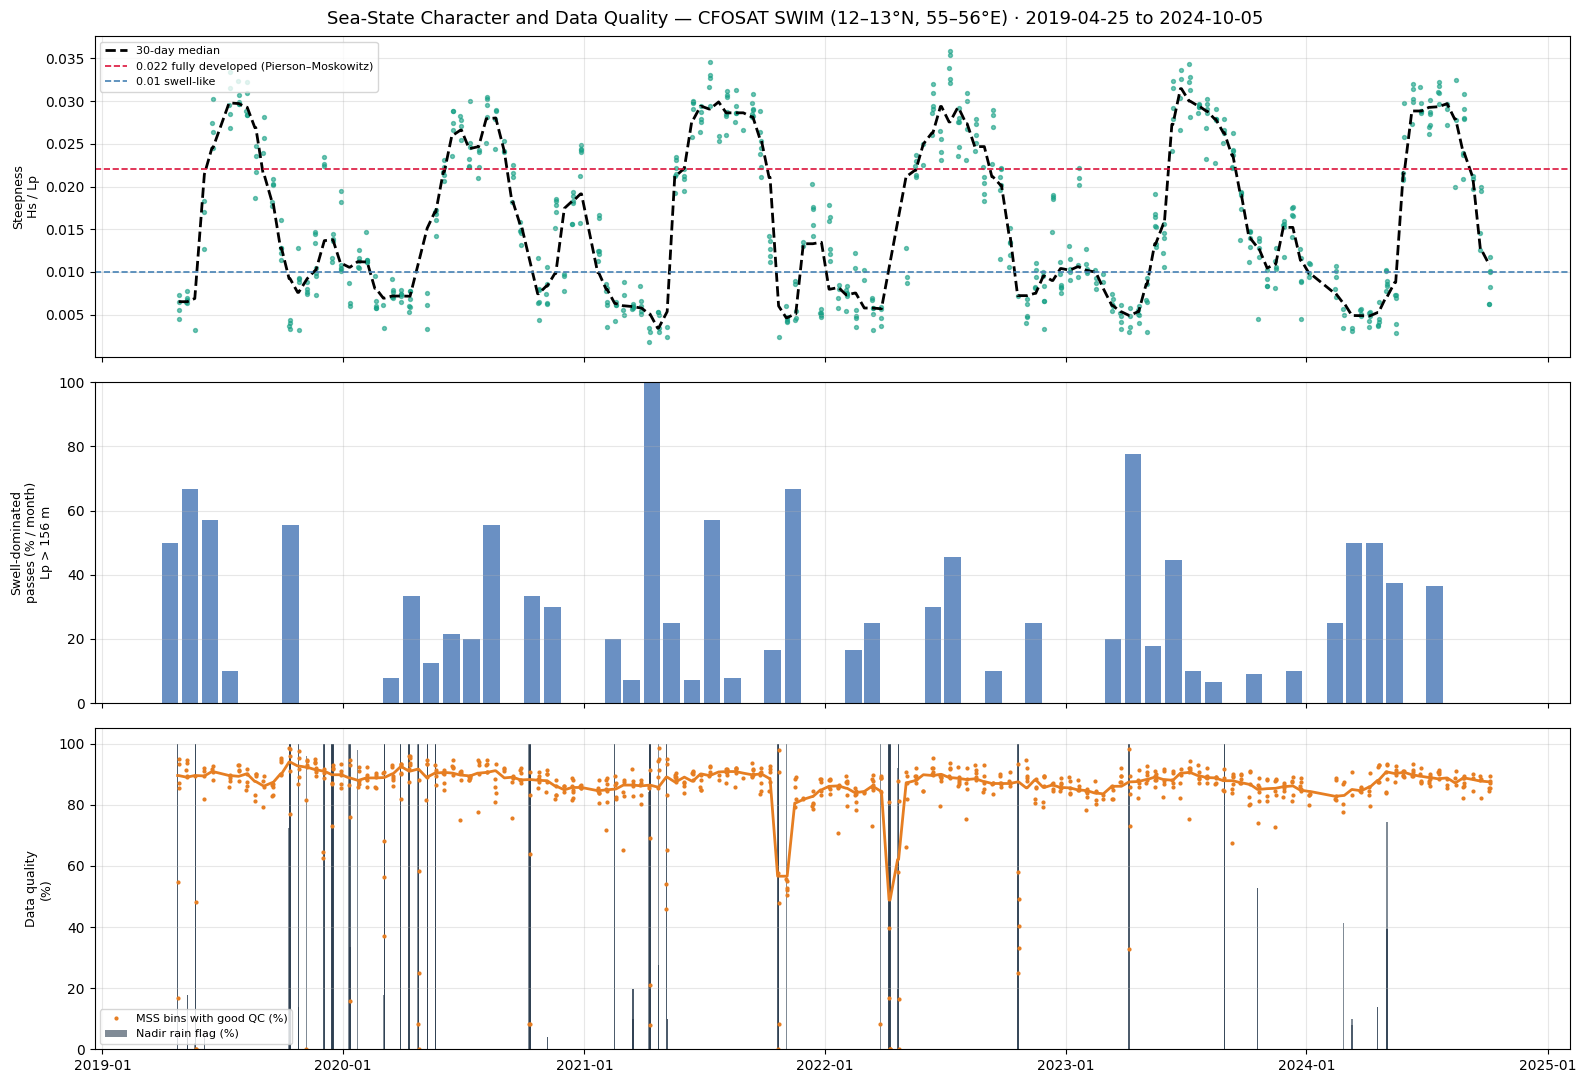

In [15]:
DATE_START = "2019-04-25"        
DATE_END   = "2024-10-05"
time_vals = xds["TIME"].values
DATE_START = DATE_START or pd.Timestamp(time_vals[0]).strftime("%Y-%m-%d")
DATE_END   = DATE_END   or pd.Timestamp(time_vals[-1]).strftime("%Y-%m-%d")

sub = xds.sel(TIME=slice(DATE_START, DATE_END))
swh = qc("SWH_CALIBRATED_NDBC", sub).to_series()
lp  = qc("Lp_CALIBRATED_NDBC", sub).to_series()

steep = (swh / lp).dropna()
L_SWELL = 2 * np.pi / K_SWELL                                    # ≈ 156 m
lp_ok   = lp.dropna()
swell_pct = (lp_ok > L_SWELL).resample("1MS").mean() * 100
n_month   = lp_ok.resample("1MS").size()
swell_pct = swell_pct.where(n_month >= 3)

good_pct = (sub[f"{SPEC_VAR}_quality_control"].isin(GOOD)
            .mean(("WAVENUMBER", "DIRECTION")).to_series() * 100)
rain = sub["NADIR_RAIN_PERCENTAGE"].to_series()
if rain.max() > 100:                                             # stored as percent x 100
    rain = rain / 100

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(16, 11), sharex=True)

# Wave steepness
ax1.scatter(steep.index, steep.values, s=8, color="#16a085", alpha=0.6)
ax1.plot(steep.index, steep.rolling("30D", center=True, min_periods=3).median(),
         color="k", lw=2, ls="--", label="30-day median")
ax1.axhline(0.022, color="crimson", ls="--", lw=1.2, label="0.022 fully developed (Pierson–Moskowitz)")
ax1.axhline(0.01, color="steelblue", ls="--", lw=1.2, label="0.01 swell-like")
ax1.set_ylabel("Steepness\nHs / Lp", fontsize=9)
ax1.legend(fontsize=8, loc="upper left")
ax1.grid(True, alpha=0.3)

# Swell-dominated fraction
ax2.bar(swell_pct.index, swell_pct.values, width=25, align="edge", color="#4575b4", alpha=0.8)
ax2.set_ylim(0, 100)
ax2.set_ylabel("Swell-dominated\npasses (% / month)\nLp > 156 m", fontsize=9)
ax2.grid(True, alpha=0.3)

# Data quality
ax3.plot(good_pct.index, good_pct.values, ".", ms=4, color="#e67e22", label=f"{SPEC_VAR} bins with good QC (%)")
ax3.plot(good_pct.index, good_pct.rolling("30D", center=True, min_periods=3).median(),
         color="#e67e22", lw=2)
ax3.bar(rain.index, rain.values, width=2, color="#2c3e50", alpha=0.6, label="Nadir rain flag (%)")
ax3.set_ylim(0, 105)
ax3.set_ylabel("Data quality\n(%)", fontsize=9)
ax3.legend(fontsize=8, loc="lower left")
ax3.grid(True, alpha=0.3)
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

fig.suptitle(
    f"Sea-State Character and Data Quality — CFOSAT SWIM ({BOX_NAME}) · {DATE_START} to {DATE_END}",
    fontsize=13,
)
plt.tight_layout()
plt.show()

## Seasonal Wave Spectra

Median omnidirectional spectra (interquartile range shaded) grouped by season, using every valid pass in the period:
- **DJF** (Dec–Feb): austral summer / boreal winter
- **MAM** (Mar–May): transition
- **JJA** (Jun–Aug): austral winter / boreal summer. Southern Ocean storm season, and the south-west monsoon in the northern Indian Ocean
- **SON** (Sep–Nov): transition

The **left panel** shows absolute energy (log scale): how much more energetic one season is than another.
The **right panel** normalises each season by its own peak to compare **spectral shape**: a peak further left means longer
dominant waves (more swell); a broader spectrum means a mix of swell and wind sea.
Grouping by season pools roughly 150–250 passes per curve, which is why these spectra are much smoother than any single pass.
The median and IQR are used instead of mean ± σ because the passes in a season span calm and storm conditions,
and the mean − σ would go negative.

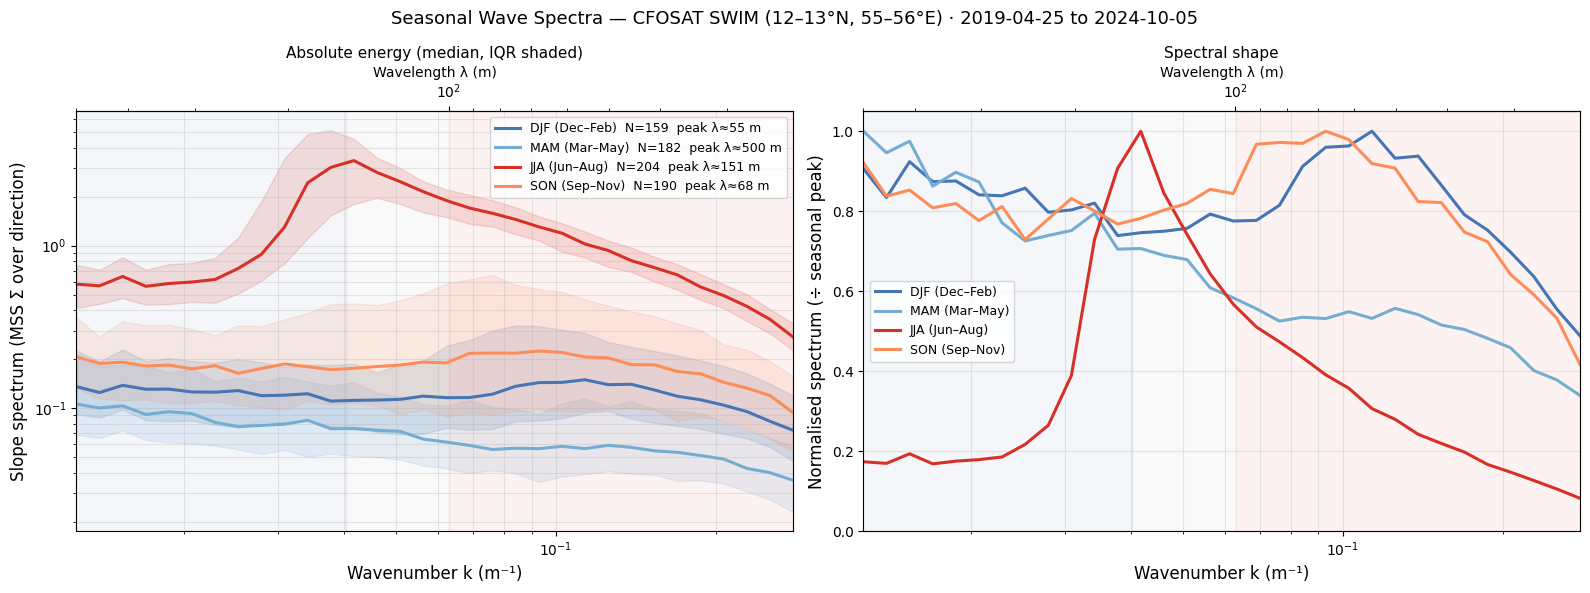

In [17]:
DATE_START = "2019-04-25"        
DATE_END   = "2024-10-05"
time_vals = xds["TIME"].values
DATE_START = DATE_START or pd.Timestamp(time_vals[0]).strftime("%Y-%m-%d")
DATE_END   = DATE_END   or pd.Timestamp(time_vals[-1]).strftime("%Y-%m-%d")

sub    = xds.sel(TIME=slice(DATE_START, DATE_END))
omni   = omni_spectrum(sub)
k      = xds["WAVENUMBER"].values
months = omni.TIME.dt.month.values

seasons = {
    "DJF (Dec–Feb)": ([12, 1, 2],  "#4575b4"),
    "MAM (Mar–May)": ([3, 4, 5],   "#74add1"),
    "JJA (Jun–Aug)": ([6, 7, 8],   "#d73027"),
    "SON (Sep–Nov)": ([9, 10, 11], "#fc8d59"),
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

for season, (month_list, color) in seasons.items():
    s = omni.isel(TIME=np.isin(months, month_list))
    if s.sizes["TIME"] < 3:
        continue
    med = s.median("TIME")
    q25, q75 = s.quantile(0.25, "TIME"), s.quantile(0.75, "TIME")
    peak = float(med.max())
    lam_p = k2wl(k[int(med.argmax())])
    label = f"{season}  N={s.sizes['TIME']}  peak λ≈{lam_p:.0f} m"

    ax1.plot(k, med, color=color, lw=2.2, label=label)
    ax1.fill_between(k, q25, q75, color=color, alpha=0.15)
    ax2.plot(k, med / peak, color=color, lw=2.2, label=season)

for ax in (ax1, ax2):
    for klo, khi, col, lbl in BANDS:
        ax.axvspan(klo or k.min(), khi or k.max(), color=col, alpha=0.06)
    ax.set_xscale("log")
    ax.set_xlim(k.min(), k.max())
    ax.set_xlabel("Wavenumber k (m⁻¹)", fontsize=12)
    top = ax.secondary_xaxis("top", functions=(k2wl, k2wl))
    top.set_xlabel("Wavelength λ (m)", fontsize=10)
    ax.grid(True, alpha=0.3, which="both")

ax1.set_yscale("log")
ax1.set_ylabel(f"Slope spectrum ({SPEC_VAR} Σ over direction)", fontsize=12)
ax1.set_title("Absolute energy (median, IQR shaded)", fontsize=11)
ax1.legend(fontsize=9)
ax2.set_ylim(0, 1.05)
ax2.set_ylabel("Normalised spectrum (÷ seasonal peak)", fontsize=12)
ax2.set_title("Spectral shape", fontsize=11)
ax2.legend(fontsize=9)

fig.suptitle(
    f"Seasonal Wave Spectra — CFOSAT SWIM ({BOX_NAME}) · {DATE_START} to {DATE_END}",
    fontsize=13,
)
plt.tight_layout()
plt.show()

## SWIM Calibration and Model Comparison

Pass-by-pass comparison of the three calibrated parameters (only passes where both values pass QC):
- **Top row: raw SWIM vs NDBC-calibrated.** This shows the correction that buoy calibration applies.
  A linear fit with slope ≠ 1 or an offset ≠ 0 is the calibration itself, not an error
- **Bottom row: WW3 hindcast vs NDBC-calibrated SWIM.** Independent validation against a wave model.
  It is drawn only if the box has valid WW3 values (in some boxes `*_WW3` is entirely flag 9, missing)

| Statistic | Meaning |
|---|---|
| **bias** | mean(y − x): systematic over- or under-estimation |
| **RMSE** | typical size of the difference |
| **r** | correlation: how well the two track each other |
| **fit** | least-squares line y = a·x + b |

Points are coloured by month to show whether disagreement is seasonal, for example only during high-swell months.

No valid WW3 values in box 12–13°N, 55–56°E: showing the raw vs calibrated comparison only.


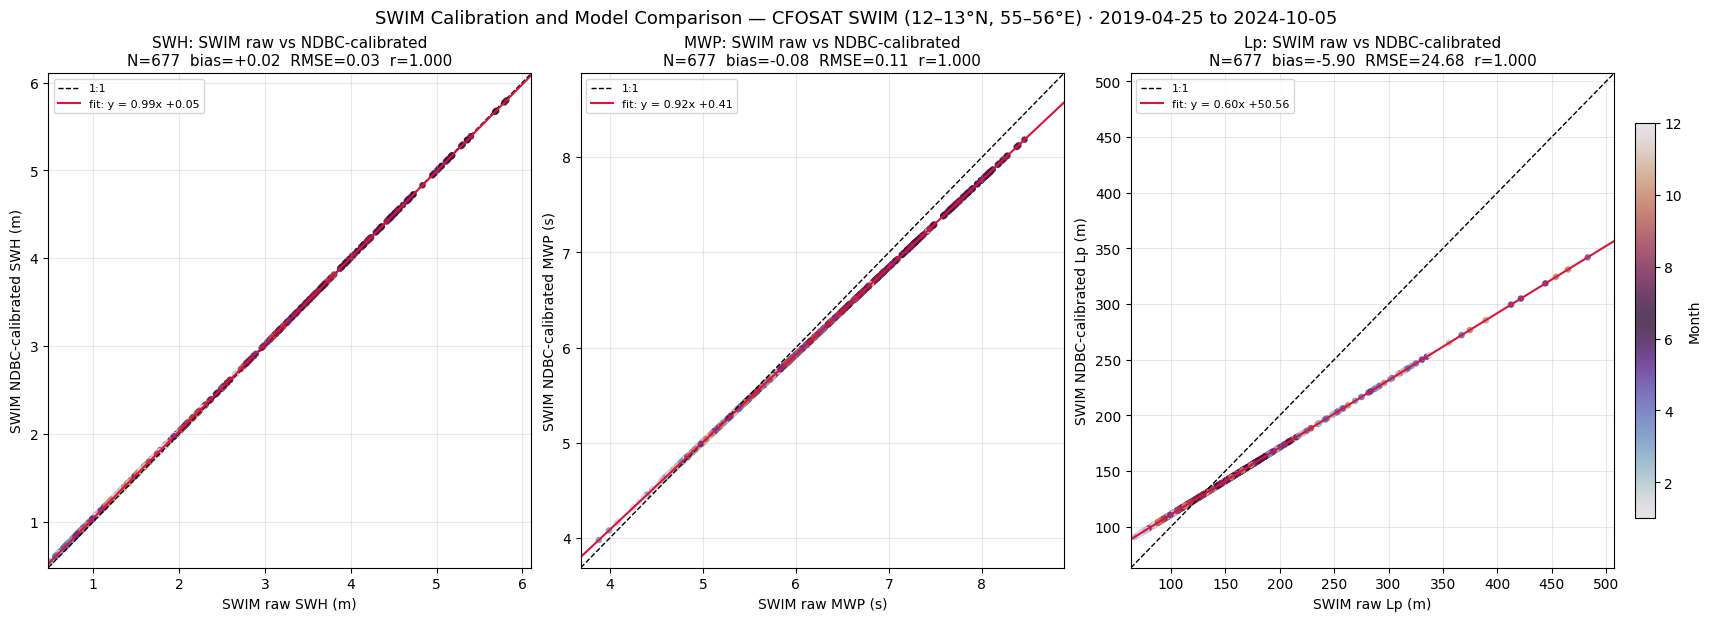

In [18]:
DATE_START = "2019-04-25"        
DATE_END   = "2024-10-05"
time_vals = xds["TIME"].values
DATE_START = DATE_START or pd.Timestamp(time_vals[0]).strftime("%Y-%m-%d")
DATE_END   = DATE_END   or pd.Timestamp(time_vals[-1]).strftime("%Y-%m-%d")

sub   = xds.sel(TIME=slice(DATE_START, DATE_END))
PARAMS = {"SWH": "SWH (m)", "MWP": "MWP (s)", "Lp": "Lp (m)"}
has_ww3 = any(qc(f"{v}_WW3", sub).notnull().any() for v in PARAMS)
rows = [("", "SWIM raw")] + ([("_WW3", "WW3 hindcast")] if has_ww3 else [])
if not has_ww3:
    print(f"No valid WW3 values in box {BOX_NAME}: showing the raw vs calibrated comparison only.")

fig, axes = plt.subplots(len(rows), 3, figsize=(17, 5.5 * len(rows) + 0.6), squeeze=False, layout="constrained")
sc = None

for r_i, (suffix, xlabel) in enumerate(rows):
    for c_i, (var, unit) in enumerate(PARAMS.items()):
        ax = axes[r_i, c_i]
        d = pd.DataFrame({
            "x": qc(f"{var}{suffix}", sub).to_series(),
            "y": qc(f"{var}_CALIBRATED_NDBC", sub).to_series(),
        }).dropna()

        if len(d) < 3:
            ax.text(0.5, 0.5, f"Not enough co-valid {var}{suffix or ' (raw)'} values",
                    ha="center", va="center", transform=ax.transAxes)
            ax.set_title(f"{var}: {xlabel} vs NDBC-calibrated", fontsize=11)
            continue

        x, y = d["x"], d["y"]
        bias = (y - x).mean()
        rmse = np.sqrt(((y - x) ** 2).mean())
        r    = np.corrcoef(x, y)[0, 1]
        a, b = np.polyfit(x, y, 1)
        lo   = min(x.min(), y.min()) * 0.95
        hi   = max(x.max(), y.max()) * 1.05

        sc = ax.scatter(x, y, c=d.index.month, cmap="twilight", vmin=1, vmax=12, s=14, alpha=0.8)
        ax.plot([lo, hi], [lo, hi], "k--", lw=1, label="1:1")
        ax.plot([lo, hi], [a * lo + b, a * hi + b], color="crimson", lw=1.5,
                label=f"fit: y = {a:.2f}x {b:+.2f}")
        ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
        ax.set_xlabel(f"{xlabel} {unit}", fontsize=10)
        ax.set_ylabel(f"SWIM NDBC-calibrated {unit}", fontsize=10)
        ax.set_title(f"{var}: {xlabel} vs NDBC-calibrated\n"
                     f"N={len(d):,}  bias={bias:+.2f}  RMSE={rmse:.2f}  r={r:.3f}", fontsize=11)
        ax.legend(fontsize=8, loc="upper left")
        ax.grid(True, alpha=0.3)

if sc is not None:
    fig.colorbar(sc, ax=axes, label="Month", shrink=0.8, pad=0.01)
fig.suptitle(
    f"SWIM Calibration and Model Comparison — CFOSAT SWIM ({BOX_NAME}) · {DATE_START} to {DATE_END}",
    fontsize=13,
)
plt.show()